<a href="https://colab.research.google.com/github/natalie-olson/YOLO_OCR_github/blob/main/ThreeInOne.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#3 in 1
#Yolo Model, inference, crop, ocr

In [1]:
#Yolo - Spine COunter method
#Dependancies
!pip install ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [3]:
from roboflow import Roboflow

rf = Roboflow(api_key="TWUuUeF5DOemh1YHnr3o")
project = rf.workspace("natalies-workspace-nfy7j").project("spinecounternatalie")
version = project.version(2)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SpineCounterNatalie-2 in yolo26:: 100%|██████████| 411/411 [00:00<00:00, 970.77it/s]


In [4]:
from ultralytics import YOLO
# Load the best trained weights

best_model = YOLO(f"/content/best(2).pt")

# Run inference on a test image
metrics = best_model.val()  # Validate on the validation set

Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4161.1±1048.2 MB/s, size: 700.9 KB)
val: Scanning /content/SpineCounterNatalie-2/valid/labels... 41 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 1.4Kit/s 0.0s
val: New cache created: /content/SpineCounterNatalie-2/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.7s/it 14.0s
                   all         41        204      0.985      0.979      0.992       0.83
Speed: 4.6ms preprocess, 234.1ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/runs/detect/val-2


In [5]:
#Testing
results = best_model.predict(source=f"/content/SpineCounterNatalie-2/test/images", save=True)
# Access text-based metrics directly
print("mAP50-95:", metrics.box.map)    # Mean Average Precision (mAP) 50-95
print("mAP50:", metrics.box.map50)     # mAP at IoU threshold 0.50
print("Precision:", metrics.box.mp)    # Mean Precision across classes
print("Recall:", metrics.box.mr)       # Mean Recall across classes

# Interact with the confusion matrix raw data
print("\nRaw Confusion Matrix Array:")
print(metrics.confusion_matrix.matrix)

# 5. Convert the confusion matrix to a Pandas DataFrame
print("\nConfusion Matrix DataFrame:")
print(metrics.confusion_matrix.to_df())



image 1/20 /content/SpineCounterNatalie-2/test/images/20260805_121743_heic.rf.9479546e769d7de1945ed71f86757f06.jpg: 480x640 2 BookSpines, 241.7ms
image 2/20 /content/SpineCounterNatalie-2/test/images/20260805_121935_heic.rf.81f2cf48da9aa8121484e909efa6396a.jpg: 480x640 6 BookSpines, 218.0ms
image 3/20 /content/SpineCounterNatalie-2/test/images/20260805_122202_heic.rf.bef5c8d32ffa9cae84369fbcee3ba266.jpg: 480x640 6 BookSpines, 207.0ms
image 4/20 /content/SpineCounterNatalie-2/test/images/20260805_122325_heic.rf.836b0a8d5f01b9987cbd0dac82efdbc0.jpg: 480x640 1 BookSpine, 205.3ms
image 5/20 /content/SpineCounterNatalie-2/test/images/20260805_122601_heic.rf.b8bda4cc121fbd19035a19260fe89d84.jpg: 480x640 5 BookSpines, 230.6ms
image 6/20 /content/SpineCounterNatalie-2/test/images/20260805_122635_heic.rf.abe874724594f6ed2c2b98f9ef5df087.jpg: 480x640 6 BookSpines, 205.0ms
image 7/20 /content/SpineCounterNatalie-2/test/images/20260805_122946_heic.rf.ba4012a5a8672e4dd107721d5fa8db59.jpg: 480x640 


image 1/1 /content/SpineCounterNatalie-2/test/images/20260805_121743_heic.rf.9479546e769d7de1945ed71f86757f06.jpg: 480x640 2 BookSpines, 158.6ms
Speed: 7.7ms preprocess, 158.6ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)
Full annotated image with bounding boxed uncropped


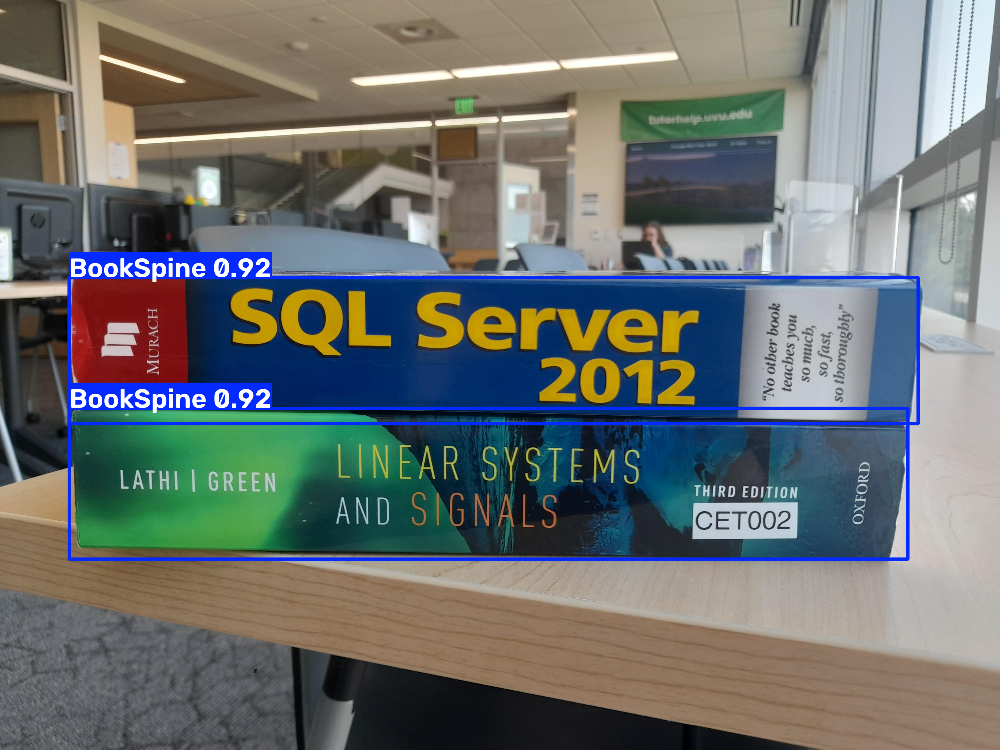

In [9]:
#Part 2. Show image and bounding box. Selective.
import cv2

og_imgpath= "/content/SpineCounterNatalie-2/test/images/20260805_121743_heic.rf.9479546e769d7de1945ed71f86757f06.jpg"
#test image to display
results = best_model(og_imgpath, conf=0.25)

# 3. Retrieve the annotated image array
# Ultralytics natively plots bounding boxes, labels, and confidence scores
annotated_frame = results[0].plot()
print("Full annotated image with bounding boxed uncropped")
# 4. Local deployment display window
from google.colab.patches import cv2_imshow
cv2_imshow(annotated_frame)

#Show Bounding box values

#Crop to bounding box value

#standardizse cropped image size.

In [12]:
img_original = cv2.imread(og_imgpath)
h_img, w_img = img_original.shape[:2]
print(h_img, w_img) # 3000 x 4000

#Show Bounding box values
boxes = results[0].boxes
#print(boxes)
#Crop to bounding box value

#standardizse cropped image size.
STANDARDIZED_SIZE = (64, 64) # For now

3000 4000
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 0.])
conf: tensor([0.9193, 0.9159])
data: tensor([[2.7677e+02, 1.1104e+03, 3.6720e+03, 1.6945e+03, 9.1928e-01, 0.0000e+00],
        [2.7782e+02, 1.6335e+03, 3.6312e+03, 2.2367e+03, 9.1594e-01, 0.0000e+00]])
id: None
is_track: False
orig_shape: (3000, 4000)
shape: torch.Size([2, 6])
xywh: tensor([[1974.3931, 1402.4487, 3395.2500,  584.0682],
        [1954.4917, 1935.0896, 3353.3413,  603.1930]])
xywhn: tensor([[0.4936, 0.4675, 0.8488, 0.1947],
        [0.4886, 0.6450, 0.8383, 0.2011]])
xyxy: tensor([[ 276.7681, 1110.4146, 3672.0181, 1694.4828],
        [ 277.8210, 1633.4930, 3631.1624, 2236.6860]])
xyxyn: tensor([[0.0692, 0.3701, 0.9180, 0.5648],
        [0.0695, 0.5445, 0.9078, 0.7456]])


In [16]:
import os
from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR = "/content/drive/MyDrive/YOLO_Cropped_Images"

KeyboardInterrupt: 


[Detection 1] Class ID: 0 | Conf: 0.92
    Coordinates (xyxy): [276, 1110, 3672, 1694]
    Standardized Crop Size: (64, 64)


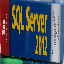


[Detection 2] Class ID: 0 | Conf: 0.92
    Coordinates (xyxy): [277, 1633, 3631, 2236]
    Standardized Crop Size: (64, 64)


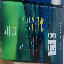

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import files

for i, box in enumerate(boxes):
    # Get class ID and confidence score
    class_id = int(box.cls[0].item())
    conf = box.conf[0].item()

    # Extract bounding box coordinates in xyxy format (pixels)
    # format: [xmin, ymin, xmax, ymax]
    xyxy = box.xyxy[0].tolist()
    xmin, ymin, xmax, ymax = map(int, xyxy)

    # Ensure coordinates stay within the physical image boundaries
    xmin, ymin = max(0, xmin), max(0, ymin)
    xmax, ymax = min(w_img, xmax), min(h_img, ymax)

    # --- Show Bounding box values ---
    print(f"\n[Detection {i+1}] Class ID: {class_id} | Conf: {conf:.2f}")
    print(f"    Coordinates (xyxy): [{xmin}, {ymin}, {xmax}, {ymax}]")

    # --- Crop to bounding box value ---
    crop = img_original[ymin:ymax, xmin:xmax]

    if crop.size == 0:
        print("    Warning: Empty crop boundary. Skipping.")
        continue

    # --- Standardize cropped image size ---
    crop_resized = cv2.resize(crop, STANDARDIZED_SIZE)

#Save image to runtime
    #filename = f"crop_det{i+1}_class{class_id}.jpg"
    #full_save_path = os.path.join(OUTPUT_DIR, filename)

    # Save the file to the local disk/runtime
    #cv2.imwrite(full_save_path, crop_resized)
    #print(f"Saved: {filename}")

    # Display the final standardized individual crop inside Colab
    print(f"    Standardized Crop Size: {crop_resized.shape[:2]}")
    cv2_imshow(crop_resized)

filename = "cropped_standardized.jpg"
cv2.imwrite(filename, crop_resized)

# 2. Trigger the browser download to your local machine
files.download(filename)

In [ ]:
#Store cropped images or feed right into ocr?

#Keep the height, width and some extended padding.

#standardize the size

In [18]:
!pip install opencv-python
!pip install pytesseract
!sudo apt-get install tesseract-ocr

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
